<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/ex6Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment Analysis Using NLP — Tweet Classification

**Level:** Beginner-friendly, intermediate experiment  
**Dataset:** `test.csv` (tweet text with sentiment labels)  
**Goal:** Predict whether a tweet is **positive, neutral, or negative** using Natural Language Processing (NLP).

This is more than a basic word-count experiment: we will explore the dataset, clean text, convert words into TF-IDF features, train and compare two machine-learning models, evaluate them with multiple metrics, inspect incorrect predictions, and test custom sentences.

> **Important:** We will use the `text` column as the input and `sentiment` as the target. Other columns (country, age, population, etc.) are not needed for this text-only experiment. This helps keep the experiment focused on NLP.


## 1. Learning outcomes

By the end, you should understand:
- What sentiment analysis and text classification mean.
- Why text needs preprocessing before machine learning.
- How TF-IDF turns text into numerical features.
- How Logistic Regression and Multinomial Naive Bayes classify text.
- How to interpret accuracy, precision, recall, F1-score, and a confusion matrix.
- How to inspect model mistakes and predict sentiment for new text.

### Workflow

`Load data → Inspect labels → Clean text → Train/test split → TF-IDF → Train models → Evaluate → Error analysis → Try your own text`


In [1]:
# 2. Import libraries
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 2. Load the CSV file

If you are running this notebook in **Google Colab**, upload `test.csv` when prompted. If the file is already in the same folder as the notebook, the code will read it directly.

The uploaded dataset uses a Windows-style text encoding in some environments, so the loader tries common encodings instead of assuming UTF-8.


In [2]:
# Run this cell. In Google Colab, upload test.csv if it is not already available.
import os

file_path = "test.csv"

if not os.path.exists(file_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Place test.csv in the same folder as this notebook, then run this cell again."
        )

data = None
last_error = None
for encoding in ["utf-8", "cp1252", "latin1", "utf-8-sig"]:
    try:
        data = pd.read_csv(file_path, encoding=encoding)
        print(f"Loaded using encoding: {encoding}")
        break
    except UnicodeDecodeError as error:
        last_error = error

if data is None:
    raise last_error

print("Dataset shape:", data.shape)
display(data.head())


Saving test.csv to test.csv
Loaded using encoding: cp1252
Dataset shape: (4815, 9)


,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346.0,652860.0,60.0
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797.0,27400.0,105.0
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044.0,2381740.0,18.0
3,01082688c6,happy bday!,positive,morning,46-60,Andorra,77265.0,470.0,164.0
4,33987a8ee5,http://twitpic.com/4w75p - I like it!!,positive,noon,60-70,Angola,32866272.0,1246700.0,26.0


In [3]:
# 3. Inspect columns, missing values, and data types
print("Columns:")
print(data.columns.tolist())

print("\\nData types:")
display(data.dtypes.to_frame("data_type"))

print("\\nMissing values:")
display(data.isna().sum().to_frame("missing_count"))

print("\\nDuplicate rows:", data.duplicated().sum())


Columns:
['textID', 'text', 'sentiment', 'Time of Tweet', 'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)', 'Density (P/Km²)']
\nData types:


,data_type
textID,object
text,object
sentiment,object
Time of Tweet,object
Age of User,object
Country,object
Population -2020,float64
Land Area (Km²),float64
Density (P/Km²),float64


\nMissing values:


,missing_count
textID,1281
text,1281
sentiment,1281
Time of Tweet,1281
Age of User,1281
Country,1281
Population -2020,1281
Land Area (Km²),1281
Density (P/Km²),1281


\nDuplicate rows: 1280


## 3. Prepare the text and target label

We will:
1. Keep rows that have both text and a sentiment label.
2. Remove duplicate text-label pairs.
3. normalize labels to lowercase.
4. create a lightweight text-cleaning function.

We will **not** remove every stop word or stem every word. Words such as “not” can reverse sentiment (“good” vs “not good”), so aggressive cleaning may remove useful meaning. TF-IDF will handle the conversion to numbers.


In [4]:
# Keep only the columns needed for this NLP task
required_columns = {"text", "sentiment"}
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

df = data[["text", "sentiment"]].copy()
df = df.dropna(subset=["text", "sentiment"])
df["text"] = df["text"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()
df = df[(df["text"] != "") & (df["sentiment"] != "")]
df = df.drop_duplicates(subset=["text", "sentiment"]).reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Unique labels:", sorted(df["sentiment"].unique()))
display(df.head())


Rows after cleaning: 3533
Unique labels: ['negative', 'neutral', 'positive']


,text,sentiment
0,Last session of the day http://twitpic.com/67ezh,neutral
1,Shanghai is also really exciting (precisely --...,positive
2,"Recession hit Veronique Branquinho, she has to...",negative
3,happy bday!,positive
4,http://twitpic.com/4w75p - I like it!!,positive


,number_of_tweets
sentiment,
neutral,1430
positive,1103
negative,1000


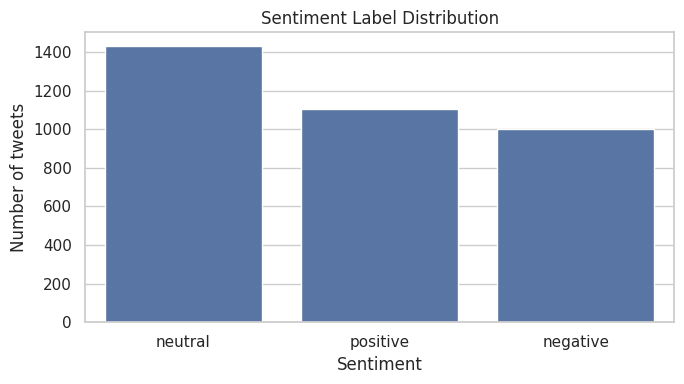

In [5]:
# Visualize how many examples each sentiment class has
label_counts = df["sentiment"].value_counts()
display(label_counts.to_frame("number_of_tweets"))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="sentiment", order=label_counts.index)
plt.title("Sentiment Label Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()


### Why check label distribution?

If one sentiment appears much more often than the others, a model can look accurate while performing poorly on the smaller classes. That is why we will also examine **precision, recall, F1-score, and the confusion matrix**, rather than relying only on accuracy.


## 4. Clean text

This function lowercases text, removes URLs and user mentions, and keeps letters, numbers, apostrophes, and spaces. It is intentionally modest: hashtags are kept as words, and negation words are not removed.

The original text is retained in `df`; a cleaned copy is used for modelling.


In [6]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)  # URLs
    text = re.sub(r"@\\w+", " ", text)                       # user mentions
    text = re.sub(r"#(\\w+)", r"\\1", text)                  # #happy -> happy
    text = re.sub(r"[^a-z0-9'\\s]", " ", text)                # punctuation/emojis
    text = re.sub(r"\\s+", " ", text).strip()                 # extra spaces
    return text

df["clean_text"] = df["text"].apply(clean_text)

for i in range(min(5, len(df))):
    print("Original:", df.loc[i, "text"])
    print("Cleaned :", df.loc[i, "clean_text"])
    print("-" * 70)


Original: Last session of the day  http://twitpic.com/67ezh
Cleaned : last session of the day  http   twitpic com 67ezh
----------------------------------------------------------------------
Original: Shanghai is also really exciting (precisely -- skyscrapers galore). Good tweeps in China:  (SH)  (BJ).
Cleaned : shanghai is also really exciting  precisely    skyscrapers galore   good tweeps in china    sh    bj
----------------------------------------------------------------------
Original: Recession hit Veronique Branquinho, she has to quit her company, such a shame!
Cleaned : recession hit veronique branquinho  she has to quit her company  such a shame
----------------------------------------------------------------------
Original: happy bday!
Cleaned : happy bday
----------------------------------------------------------------------
Original: http://twitpic.com/4w75p - I like it!!
Cleaned : http   twitpic com 4w75p   i like it
--------------------------------------------------------

## 5. Split into training and testing data

The training set teaches the model; the test set checks performance on examples it did not train on. A **stratified split** tries to preserve the proportion of each sentiment class in both sets.

We split before fitting TF-IDF. Since TF-IDF is inside each scikit-learn pipeline, its vocabulary and IDF values are learned from training text only, reducing data leakage.


In [7]:
X = df["clean_text"]
y = df["sentiment"]

# Stratification needs at least two examples per class
class_counts = y.value_counts()
if class_counts.min() < 2:
    raise ValueError("Each sentiment class needs at least 2 rows for a stratified split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples :", len(X_test))
print("\\nTraining label proportions:")
display(y_train.value_counts(normalize=True).round(3).to_frame("proportion"))


Training examples: 2826
Testing examples : 707
\nTraining label proportions:


,proportion
sentiment,
neutral,0.405
positive,0.312
negative,0.283


## 6. Convert text into TF-IDF features

Computers cannot directly learn from raw sentences. **TF-IDF** gives each word a numerical weight:
- Words frequent in one text can be useful.
- Words appearing in almost every text tend to be less informative.
- `ngram_range=(1, 2)` uses single words and two-word phrases, which can help capture expressions such as “not good”.
- `min_df=2` ignores terms that appear in only one training document.

We use a pipeline so vectorization and classification stay together.


In [8]:
def make_tfidf_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

models = {
    "Logistic Regression": make_tfidf_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Multinomial Naive Bayes": make_tfidf_pipeline(
        MultinomialNB(alpha=0.5)
    )
}

print("Models prepared:", list(models.keys()))


Models prepared: ['Logistic Regression', 'Multinomial Naive Bayes']


## 7. Train and compare models

We will compare two widely used text-classification models:
- **Logistic Regression:** a strong, interpretable baseline for TF-IDF text features.
- **Multinomial Naive Bayes:** a fast probabilistic model often used for text classification.

The scores below are measured on the same held-out test set.


In [9]:
results = []
trained_models = {}

for model_name, model in models.items():
    print(f"Training: {model_name}")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": __import__("sklearn.metrics").metrics.f1_score(
            y_test, predictions, average="macro"
        ),
        "Weighted F1": __import__("sklearn.metrics").metrics.f1_score(
            y_test, predictions, average="weighted"
        )
    })

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
display(results_df.round(4))


Training: Logistic Regression
Training: Multinomial Naive Bayes


,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.6535,0.6590,0.6543
1,Multinomial Naive Bayes,0.5997,0.5848,0.5913


### How to read these scores

- **Accuracy:** fraction of all test examples classified correctly.
- **Macro F1:** calculates F1 separately for each class and averages them equally. Useful when class sizes differ.
- **Weighted F1:** averages each class's F1 while accounting for its number of examples.

For this experiment, use **Macro F1** as the primary comparison metric, then inspect per-class results before choosing a model. The best score can vary with the dataset and split.


## 8. Detailed evaluation of the best model

We select the model with the highest test Macro F1 score for the following diagnostic steps. This is a learning comparison; for a final research project, tune hyperparameters on validation data or cross-validation rather than repeatedly selecting based on the test set.


In [10]:
from sklearn.metrics import f1_score

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Selected model: Logistic Regression
\nClassification report:
              precision    recall  f1-score   support

    negative       0.65      0.68      0.66       200
     neutral       0.60      0.62      0.61       286
    positive       0.74      0.68      0.71       221

    accuracy                           0.65       707
   macro avg       0.66      0.66      0.66       707
weighted avg       0.66      0.65      0.65       707



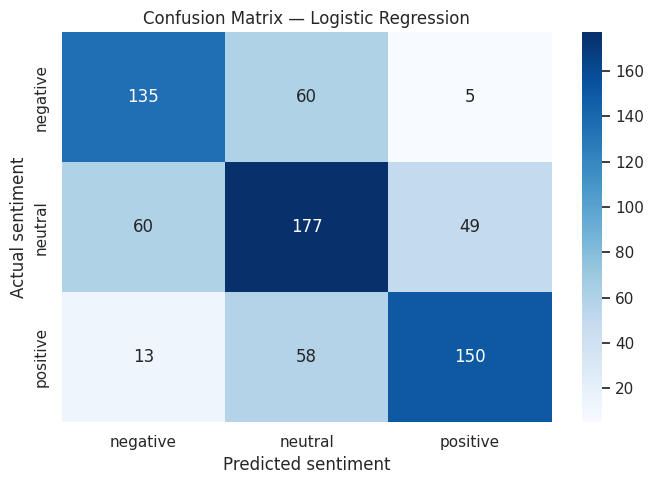

In [11]:
# Confusion matrix: rows = actual class, columns = predicted class
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()


### Confusion matrix interpretation

- The diagonal cells are correct predictions.
- Off-diagonal cells show mistakes.
- For example, if many **neutral** tweets are predicted as **positive**, the model may be confusing factual or mildly positive wording.

Always interpret the matrix using your own displayed results; do not assume a particular class is the hardest before looking at the numbers.


## 9. Error analysis: inspect incorrect predictions

Looking at mistakes is an important NLP skill. We will display some examples where the model prediction differs from the dataset label. This can reveal sarcasm, ambiguous wording, mixed emotions, or labels that are difficult to infer from text alone.


In [12]:
error_analysis = pd.DataFrame({
    "text": df.loc[X_test.index, "text"].values,
    "actual": y_test.values,
    "predicted": y_pred
})
errors = error_analysis[error_analysis["actual"] != error_analysis["predicted"]]

print(f"Incorrect predictions: {len(errors)} out of {len(error_analysis)}")
display(errors.head(15))


Incorrect predictions: 245 out of 707


,text,actual,predicted
2,"_Walker21 sadly no, I`ll be going to the killu...",neutral,negative
4,don`t think i can take a needle. watched a hor...,negative,neutral
6,shame Freud can`t follow up on those implications,negative,neutral
10,using yahoo pipes to combine feeds - doable & ...,positive,neutral
11,There mite be a article in the trib bout porti...,neutral,negative
16,.. Guess ol` Tom has another mission impossibl...,negative,neutral
18,just watched slumdog millionaire its soo gooo...,neutral,positive
19,'you said 'darling what happened? did I fall a...,positive,neutral
22,"says alright, alright... I`m going already. Sh...",neutral,positive
23,"Wow, I really hope it gets better. Asthma sucks",neutral,positive


### Questions to answer from the error table

1. Are some mistakes caused by sarcasm or jokes?
2. Do short tweets provide too little context?
3. Are positive and negative words mixed in the same tweet?
4. Could the dataset's sentiment label itself be ambiguous?

Write 2–3 observations in your project report after reviewing the actual examples.


## 10. Try your own text

Enter a sentence or tweet below. The selected model will clean it and predict a sentiment. The prediction is a model estimate, not a guaranteed understanding of the author's intent.


In [13]:
def predict_sentiment(text, model=best_model):
    cleaned = clean_text(text)
    if not cleaned:
        return "Please enter some meaningful text."
    prediction = model.predict([cleaned])[0]
    return prediction

examples = [
    "I absolutely love this phone, the camera is amazing!",
    "The delivery was late and the product was damaged.",
    "My package arrived today."
]

for sentence in examples:
    print("Text      :", sentence)
    print("Sentiment :", predict_sentiment(sentence))
    print("-" * 70)


Text      : I absolutely love this phone, the camera is amazing!
Sentiment : positive
----------------------------------------------------------------------
Text      : The delivery was late and the product was damaged.
Sentiment : neutral
----------------------------------------------------------------------
Text      : My package arrived today.
Sentiment : negative
----------------------------------------------------------------------


In [ ]:
# Change these examples to test your own sentences
my_texts = [
    "The movie was surprisingly good and enjoyable.",
    "I am not happy with this service.",
    "The meeting starts at 10 AM."
]

for sentence in my_texts:
    print(f"{sentence}  -->  {predict_sentiment(sentence)}")


## 11. Optional extension: inspect important words

For Logistic Regression, the largest positive and negative coefficients can help explain which terms influence each class. This section runs only if Logistic Regression was selected as the best model.

**Caution:** a coefficient shows association learned by the model, not proof that a word always has that sentiment. Context matters.


In [14]:
if best_name == "Logistic Regression":
    vectorizer = best_model.named_steps["tfidf"]
    classifier = best_model.named_steps["classifier"]
    feature_names = np.array(vectorizer.get_feature_names_out())
    class_names = classifier.classes_

    if len(class_names) == 2:
        coef = classifier.coef_[0]
        print("Binary classification: coefficients separate the two classes.")
        display(pd.DataFrame({
            "word_or_phrase": feature_names[np.argsort(coef)[-15:][::-1]],
            "coefficient": np.sort(coef)[-15:][::-1]
        }))
    else:
        for class_index, class_name in enumerate(class_names):
            coef = classifier.coef_[class_index]
            top_indices = np.argsort(coef)[-10:][::-1]
            print(f"Top terms associated with class: {class_name}")
            display(pd.DataFrame({
                "word_or_phrase": feature_names[top_indices],
                "coefficient": coef[top_indices]
            }))
else:
    print("Logistic Regression was not the selected model. Train or inspect that model separately to view coefficients.")


Top terms associated with class: negative


,word_or_phrase,coefficient
0,sad,2.571772
1,miss,2.442458
2,hate,2.217564
3,sorry,2.161808
4,bad,1.970046
5,stupid,1.653977
6,ugh,1.593526
7,my,1.593119
8,poor,1.578783
9,cry,1.566588


Top terms associated with class: neutral


,word_or_phrase,coefficient
0,what,1.131566
1,do you,0.935048
2,lunch,0.844563
3,can you,0.835127
4,where,0.809482
5,said,0.807898
6,me too,0.789409
7,at,0.785966
8,eating,0.764699
9,home,0.759132


Top terms associated with class: positive


,word_or_phrase,coefficient
0,love,4.079571
1,good,3.464944
2,thanks,2.800785
3,happy,2.640230
4,great,2.322750
5,nice,2.275229
6,cool,1.850445
7,amazing,1.848918
8,awesome,1.772420
9,thank,1.722837


## 12. Conclusion

In this experiment, we used NLP to classify tweet text into sentiment categories. We cleaned text, converted it into TF-IDF features, trained Logistic Regression and Multinomial Naive Bayes, compared their performance, and evaluated the selected model with a classification report and confusion matrix. Error analysis helped us inspect real misclassifications, and the prediction function lets us test new sentences.

### Limitations
- Sarcasm, slang, spelling mistakes, emojis, and context can be difficult to interpret.
- The model learns patterns from this dataset, so its performance may change on reviews, news, or text from another platform.
- Dataset labels may contain ambiguity or noise.
- Test scores estimate performance on similar data; they do not guarantee real-world performance.

### Suggested next improvements
1. Tune `ngram_range`, `min_df`, and model hyperparameters using cross-validation.
2. Compare word-level TF-IDF with character n-grams.
3. Try a pretrained transformer model such as DistilBERT for a more advanced experiment.
4. Save the trained pipeline with `joblib` for reuse in a small application.
